<a href="https://colab.research.google.com/github/Sayrinix/Entrega_S4_CDD/blob/main/S4_Sayrina_Luciano_CDD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 4 — Minería de datos, validación y volumen
**Ciencia de Datos · Semana 4 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 2) · RA3 (transversal) |
| **Duración estimada** | 1,25 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_explorado.csv`, producido en la semana 3 |
| **Producto** | Este cuaderno completo — **es la Entrega 3** |
| **Estudiante** | _Sayrina Luciano Jofré_ |

---

Esta semana pasas de **describir** a **descubrir**. Las tres técnicas de minería encuentran estructura que no se ve a simple vista; la validación decide si ese hallazgo se sostiene.

Las partes 1, 2 y 5 son **guiadas**, con los datos que trae el curso. Las partes 3 y 4 las aplicas sobre **tu propio conjunto**.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20264
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

# En Google Colab, mlxtend ya viene instalado. En local:
# !pip install mlxtend scikit-learn
print('Listo')

Listo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [40]:

# Configuración para evitar advertencias de deprecación
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---
## Parte 1 · Reglas de asociación

Una regla de asociación tiene la forma **A → B**: «quien lleva A, tiende a llevar B». Se miden con tres números, y confundirlos es el error clásico del tema.

| Métrica | Qué mide | Trampa |
|---|---|---|
| **Soporte** | Qué fracción de las canastas contiene A y B juntos | Una regla con soporte mínimo puede ser una casualidad |
| **Confianza** | De quienes llevan A, qué fracción lleva también B | **Sube sola si B es muy frecuente** |
| **Lift** | Cuántas veces más probable es B dado A, comparado con el azar | > 1 asociación real · = 1 independencia · < 1 se repelen |

In [41]:
df = pd.read_csv(RUTA + 'S4_Dataset_Transacciones_CDD.csv', sep=';')
print('Líneas:', len(df), '· Transacciones:', df['transaccion_id'].nunique(),
      '· Productos:', df['producto'].nunique())
df.head()

Líneas: 21494 · Transacciones: 4000 · Productos: 21


,transaccion_id,fecha,tienda,producto
0,T00001,2025-03-02,Norte,pan
1,T00001,2025-03-02,Norte,vino
2,T00002,2025-06-22,Oriente,azucar
3,T00002,2025-06-22,Oriente,cafe
4,T00002,2025-06-22,Oriente,fideos


### 1.1 De lista larga a matriz de canasta

Los algoritmos necesitan una matriz booleana: una fila por transacción, una columna por producto.

In [42]:
cesta = (df.assign(v=1)
           .pivot_table(index='transaccion_id', columns='producto',
                        values='v', fill_value=0)
           .astype(bool))
print('Matriz:', cesta.shape)
cesta.iloc[:5, :6]

Matriz: (4000, 21)


producto,arroz,azucar,cafe,cerveza,detergente,fideos
transaccion_id,,,,,,
T00001,False,False,False,False,False,False
T00002,False,True,True,False,False,True
T00003,False,True,False,True,False,False
T00004,True,False,False,False,False,False
T00005,False,True,False,False,False,False


In [43]:
# Frecuencia de cada producto: fíjate en los dos primeros
frecuencias = cesta.mean().sort_values(ascending=False)
frecuencias.head(8).round(3)

,0
producto,
pan,0.622
leche,0.566
palta,0.462
azucar,0.321
salsa de tomate,0.304
huevos,0.294
jamon,0.240
arroz,0.238


«pan» aparece en el 62 % de las canastas y «leche» en el 57 %. **Retén ese dato**: explica lo que viene a continuación.

### 1.2 Extraer las reglas

In [44]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(cesta, min_support=0.05, use_colnames=True)
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10)

# nos quedamos con las reglas de un producto a un producto, más fáciles de leer
reglas = reglas[(reglas['antecedents'].str.len() == 1) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: list(s)[0]) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0]))
print('Reglas encontradas:', len(reglas))

Reglas encontradas: 205


### 1.3 La trampa: ordenar por confianza

In [45]:
reglas.nlargest(8, 'confidence')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
157,palta → pan,0.392,0.850,1.368
89,fideos → salsa de tomate,0.172,0.783,2.573
20,cafe → azucar,0.147,0.747,2.327
68,cerveza → papas fritas,0.098,0.667,2.830
75,detergente → pan,0.079,0.656,1.056
186,tomate → pan,0.133,0.645,1.038
57,cafe → pan,0.127,0.643,1.035
183,queso → pan,0.144,0.637,1.024


Aparecen mezcladas dos cosas muy distintas:

- `fideos → salsa de tomate` (confianza 0,78 · **lift 2,57**) — asociación real.
- `detergente → pan` (confianza 0,66 · **lift 1,06**) — ruido.

La segunda tiene confianza alta **solo porque el pan está en casi dos tercios de las canastas**. Quien lleva detergente lleva pan con la misma probabilidad que cualquiera.

### 1.4 El mismo cálculo, ordenado por lift

In [46]:
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
68,cerveza → papas fritas,0.098,0.667,2.830
69,papas fritas → cerveza,0.098,0.415,2.830
201,queso → vino,0.064,0.280,2.743
202,vino → queso,0.064,0.623,2.743
88,salsa de tomate → fideos,0.172,0.566,2.573
89,fideos → salsa de tomate,0.172,0.783,2.573
20,cafe → azucar,0.147,0.747,2.327
21,azucar → cafe,0.147,0.458,2.327


Ahora quedan solo las asociaciones reales: cerveza con papas fritas, vino con queso, fideos con salsa, café con azúcar. **El lift corrige por la frecuencia base del consecuente**, y por eso es la métrica que decide.

### 1.5 El contraejemplo definitivo

In [47]:
for r in ['pan → leche', 'leche → pan']:
    f = reglas[reglas['regla'] == r]
    if len(f):
        print(f"{r:15s} soporte {f['support'].iloc[0]:.3f} · "
              f"confianza {f['confidence'].iloc[0]:.3f} · lift {f['lift'].iloc[0]:.3f}")

pan → leche     soporte 0.344 · confianza 0.554 · lift 0.979
leche → pan     soporte 0.344 · confianza 0.608 · lift 0.979


`leche → pan` tiene **confianza 0,61**: seis de cada diez compradores de leche llevan pan. Suena a regla fuerte.

Su **lift es 0,98**, por debajo de 1. Aparecen juntos **algo menos** de lo esperable por azar: son independientes. Si un sistema de recomendación se guiara por confianza, sugeriría pan a quien lleva leche, sin ganar nada.

> **Regla del oficio: filtra por soporte, ordena por lift, y usa la confianza solo para describir.**

### ✏️ Actividad 1.1

Extrae las reglas con **dos productos en el antecedente** (`antecedents.str.len() == 2`) y quédate con las tres de mayor lift. ¿Aportan algo que no dijeran ya las reglas simples?

In [48]:
# Tu código aquí

# Recuperar todas las reglas desde los conjuntos frecuentes
reglas_completas = association_rules(
    frecuentes,
    metric="confidence",
    min_threshold=0.10
)

# Filtrar reglas con dos productos en el antecedente
reglas_dobles = reglas_completas[
    (reglas_completas["antecedents"].str.len() == 2) &
    (reglas_completas["consequents"].str.len() == 1)
].copy()

# Seleccionar las tres reglas con mayor lift
top_3 = reglas_dobles.nlargest(3, "lift")

# Mostrar resultados
display(
    top_3[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].round(3)
)


,antecedents,consequents,support,confidence,lift
313,"(pan, papas fritas)",(cerveza),0.061,0.429,2.931
302,"(leche, papas fritas)",(cerveza),0.057,0.425,2.900
303,"(cerveza, leche)",(papas fritas),0.057,0.682,2.891


In [49]:

# Seleccionar reglas simples relacionadas con los tres productos
reglas_simples = reglas_completas[
    (reglas_completas["antecedents"].str.len() == 1) &
    (reglas_completas["consequents"].str.len() == 1)
].copy()

# Filtrar antecedentes de interés
productos = {"pan", "papas fritas", "leche", "cerveza"}

comparacion = reglas_simples[
    reglas_simples["antecedents"].apply(
        lambda x: next(iter(x)) in productos
    ) &
    reglas_simples["consequents"].apply(
        lambda x: next(iter(x)) in productos
    )
]

display(
    comparacion[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].sort_values("lift", ascending=False).round(3)
)


,antecedents,consequents,support,confidence,lift
69,(papas fritas),(cerveza),0.098,0.415,2.830
68,(cerveza),(papas fritas),0.098,0.667,2.830
66,(pan),(cerveza),0.093,0.150,1.024
67,(cerveza),(pan),0.093,0.637,1.024
62,(cerveza),(leche),0.084,0.573,1.013
63,(leche),(cerveza),0.084,0.148,1.013
133,(leche),(papas fritas),0.135,0.238,1.010
132,(papas fritas),(leche),0.135,0.572,1.010
131,(leche),(pan),0.344,0.608,0.979
130,(pan),(leche),0.344,0.554,0.979


### Reglas con dos productos en el antecedente

Se seleccionaron las tres reglas con dos productos en el antecedente que presentaron los mayores valores de lift y se compararon con sus respectivas reglas simples.

La regla `Pan + Papas fritas → Cerveza` presentó el mayor lift (2,931), con un soporte de 6,1 % y una confianza de 42,9 %. Sin embargo, la regla simple `Papas fritas → Cerveza` ya presentaba un lift elevado de 2,830 y una confianza de 41,5 %.

De manera similar, `Papas fritas + Leche → Cerveza` obtuvo un lift de 2,900, mientras que `Leche + Cerveza → Papas fritas` alcanzó 2,891. En ambos casos, los incrementos respecto de las reglas simples fueron reducidos.

Adicionalmente, las reglas individuales `Pan → Cerveza` y `Leche → Cerveza` presentaron lifts cercanos a 1, lo que sugiere que la asociación más relevante se encuentra principalmente entre papas fritas y cerveza.

**Conclusión:** Las reglas con dos antecedentes permiten identificar combinaciones más específicas, pero no aportan una mejora sustancial respecto de las reglas simples. Sus incrementos de lift son pequeños y presentan menor soporte. Por ello, las reglas simples podrían resultar más útiles para describir patrones frecuentes de compra, aunque sería necesario validar la estabilidad de estas asociaciones antes de utilizarlas para tomar decisiones.

---
## Parte 2 · Segmentación

La segmentación agrupa registros parecidos **sin que nadie haya definido los grupos**. Trabajaremos sobre el archivo de consumo eléctrico, construyendo un perfil por medidor.

In [50]:
grande = pd.read_csv(RUTA + 'S4_Dataset_Grande_CDD.csv', sep=';')
grande['fecha_hora'] = pd.to_datetime(grande['fecha_hora'], format='mixed')
grande['hora'] = grande['fecha_hora'].dt.hour
print('Filas:', f'{len(grande):,}', '· Medidores:', grande['medidor_id'].nunique())
grande.head(3)

Filas: 280,800 · Medidores: 260


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
0,M00000,2025-04-01,Hualpén,BT1,0.985,3.1,0
1,M00001,2025-04-01,Los Ángeles,BT1,0.362,3.1,0
2,M00002,2025-04-01,Hualpén,BT1,0.371,3.1,0


### 2.1 De 280.800 registros a 260 perfiles

No se segmentan las mediciones: se segmentan los **medidores**. El primer paso siempre es decidir cuál es la unidad y construir sus atributos.

In [51]:
perfil = grande.groupby('medidor_id').agg(
    consumo_medio=('consumo_kwh', 'mean'),
    variabilidad=('consumo_kwh', 'std'),
    punta=('consumo_kwh', lambda s: s.quantile(0.95)),
)
nocturno = grande[grande['hora'].isin([0, 2, 4])].groupby('medidor_id')['consumo_kwh'].mean()
perfil['razon_nocturna'] = nocturno / perfil['consumo_medio']
perfil = perfil.dropna()
print('Perfiles:', perfil.shape)
perfil.describe().round(3)

Perfiles: (260, 4)


,consumo_medio,variabilidad,punta,razon_nocturna
count,260.000,260.000,260.000,260.000
mean,1.241,0.538,2.250,0.637
std,0.650,0.282,1.179,0.009
min,0.230,0.097,0.412,0.610
25%,0.829,0.357,1.510,0.632
50%,1.082,0.469,1.959,0.637
75%,1.520,0.656,2.737,0.642
max,4.327,1.883,7.953,0.661


### 2.2 Estandarizar es obligatorio

Los algoritmos de agrupamiento miden **distancias**. Si una variable va de 0 a 7 y otra de 0 a 1, la primera domina el resultado por su escala, no por su importancia.

In [52]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

Media de cada columna tras estandarizar: [ 0. -0. -0.  0.]
Desviación de cada columna            : [1. 1. 1. 1.]


### 2.3 ¿Cuántos grupos?

No hay respuesta única. La **silueta** mide cuán separados quedan los grupos: va de −1 a 1, y valores sobre 0,5 indican una estructura clara.

In [53]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

k=2  silueta=0.506  inercia=   562.8  tamaños=[ 44 216]
k=3  silueta=0.339  inercia=   409.3  tamaños=[132  98  30]
k=4  silueta=0.335  inercia=   306.2  tamaños=[73 96 14 77]
k=5  silueta=0.336  inercia=   240.0  tamaños=[44 70  9 71 66]
k=6  silueta=0.342  inercia=   197.4  tamaños=[44 54 31  7 46 78]
k=7  silueta=0.343  inercia=   165.5  tamaños=[45  7 67 35 21 40 45]


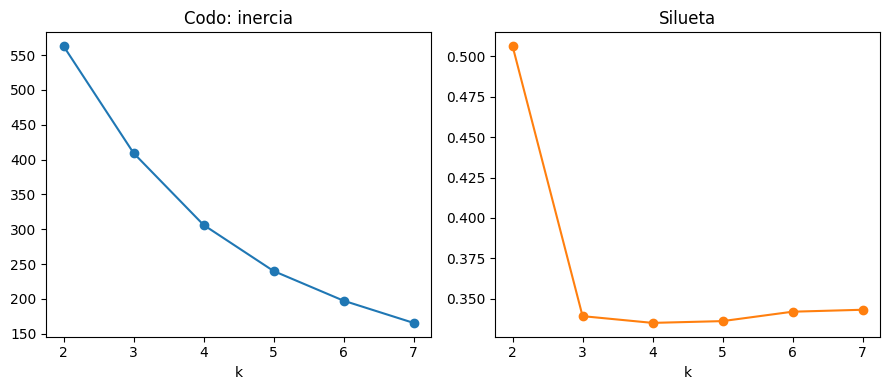

In [54]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

La silueta es máxima en **k = 2** (≈ 0,51) y cae a ≈ 0,34 desde k = 3. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

> **El número de grupos es una decisión, no un resultado.** La silueta te dice cuán separados quedan; si necesitas tres segmentos porque hay tres políticas comerciales distintas, puedes usar k = 3 **declarando que la separación es más débil**.

### 2.4 Caracterizar los grupos

Un grupo sin nombre no sirve para decidir. Después de agrupar hay que describir en qué se diferencian.

In [55]:
km = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X)
perfil['grupo'] = km.labels_

resumen = perfil.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil['grupo'].value_counts().sort_index().to_string())

,consumo_medio,variabilidad,punta,razon_nocturna
grupo,,,,
0,0.782,0.339,1.418,0.638
1,1.442,0.626,2.614,0.636
2,2.606,1.131,4.719,0.639



Tamaño de cada grupo:
grupo
0    132
1     98
2     30


### ✏️ Actividad 2.1

Mira la tabla anterior y **ponle nombre a cada grupo** en una frase, a partir de sus valores medios. Un nombre útil describe el comportamiento, no el número: «alto consumo con punta vespertina» sirve; «grupo 2» no.

_Grupo 0:_ Nivel de consumo medio más bajo

_Grupo 1:_ Nivel central de consumo medio

_Grupo 2:_ Nivel de consumo medio más alto

---
## Parte 3 · Detección de anomalías

Una anomalía es un registro que **no se parece a ninguno de los grupos**. La forma más directa de encontrarlas tras segmentar es medir la distancia de cada punto a su propio centro.

In [56]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil['distancia'] = distancias

umbral = np.percentile(distancias, 97)
anomalos = perfil[perfil['distancia'] > umbral]
print(f'Umbral (percentil 97): {umbral:.2f}')
print(f'Medidores anómalos: {len(anomalos)} de {len(perfil)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

Umbral (percentil 97): 2.49
Medidores anómalos: 8 de 260


,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,2,4.803
M00074,3.852,1.656,6.983,0.636,2,3.319
M00028,1.002,0.447,1.819,0.610,1,3.187
M00191,3.689,1.606,6.779,0.641,2,2.956
M00041,3.215,1.407,5.848,0.619,2,2.908
M00050,0.744,0.327,1.347,0.614,0,2.864
M00008,0.602,0.262,1.080,0.661,0,2.724
M00097,3.473,1.522,6.326,0.632,2,2.499


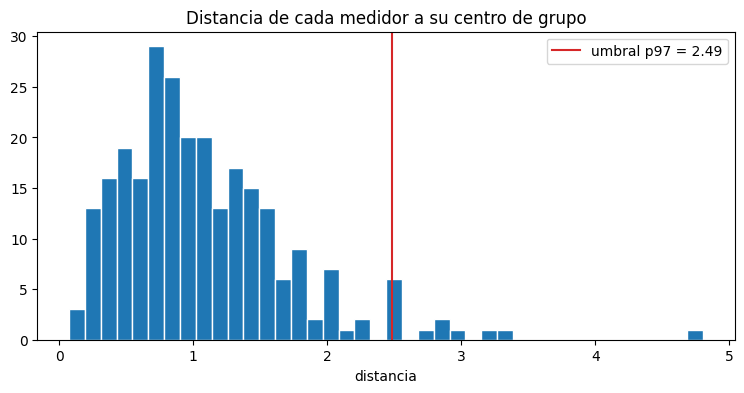

In [57]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p97 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

> **El umbral lo eliges tú.** El percentil 97 no es una ley: es una decisión sobre cuántos casos quieres revisar. Súbelo si tienes poca capacidad de revisión, bájalo si el costo de no detectar es alto. Esa decisión va declarada.

### ✏️ Actividad 3.1 — La pregunta que ninguna fórmula responde

Toma los tres medidores más anómalos y **pronúnciate sobre cada uno**: ¿es un error de registro o un fenómeno real? Apóyate en sus valores concretos y en lo que sabes del dominio.

Recuerda la semana 2: lo imposible se corrige, lo raro se conserva.

In [58]:
# Tu código aquí: mira el detalle de esos medidores en el archivo original


# Obtener los tres medidores más anómalos
medidores_extremos = (
    perfil.sort_values("distancia", ascending=False)
    .head(3).index.tolist()
)

print("Tres medidores más anómalos:")
print(medidores_extremos)

# Recuperar todos sus registros originales
detalle_medidores = grande[
    grande["medidor_id"].isin(medidores_extremos)
].copy()

# Resumen estadístico por medidor
resumen = detalle_medidores.groupby("medidor_id")["consumo_kwh"].agg(
    ["count", "min", "mean", "max", "std"]
)

resumen["negativos"] = detalle_medidores.groupby("medidor_id")["consumo_kwh"].apply(
    lambda x: (x < 0).sum()
)

resumen["faltantes"] = detalle_medidores.groupby("medidor_id")["consumo_kwh"].apply(
    lambda x: x.isna().sum()
)

display(resumen.round(3))




Tres medidores más anómalos:
['M00184', 'M00074', 'M00028']


,count,min,mean,max,std,negativos,faltantes
medidor_id,,,,,,,
M00028,1080,0.309,1.002,2.758,0.447,0,0
M00074,1080,1.188,3.852,11.745,1.656,0,0
M00184,1080,1.267,4.327,11.628,1.883,0,0


_Tu diagnóstico de los tres casos:_

### Actividad 3.1 — Diagnóstico de los tres medidores más anómalos

Se detectaron anomalías mediante la distancia euclidiana de cada medidor respecto del centroide de su grupo, utilizando como umbral exploratorio el percentil 97 (aproximadamente 2,49). Este criterio permite identificar los perfiles más alejados de los patrones representados por sus respectivos grupos.

Posteriormente, se examinaron los registros originales de los tres medidores con mayor distancia: M00184, M00074 y M00028. Cada medidor contiene 1.080 registros, sin consumos negativos ni valores faltantes en la variable `consumo_kwh`.

**1. Medidor M00184:** Presenta un consumo medio de 4,327 kWh, una desviación estándar de 1,883 y un máximo de 11,628 kWh. Estos resultados reflejan un perfil de consumo elevado y variable. Dado que no se identificaron valores negativos ni faltantes, se clasifica provisionalmente como un posible fenómeno real de demanda elevada, pendiente de verificación adicional.

**2. Medidor M00074:** Registra un consumo medio de 3,852 kWh, una desviación estándar de 1,656 y un máximo de 11,745 kWh, el mayor entre los tres casos examinados. Su comportamiento podría representar un patrón real de consumo con puntas pronunciadas. No existe evidencia suficiente para atribuirlo a un error de registro.

**3. Medidor M00028:** Presenta un consumo medio de 1,002 kWh, una desviación estándar de 0,447 y un máximo de 2,758 kWh. A diferencia de los otros dos medidores, muestra un consumo relativamente bajo y una menor variabilidad. Su clasificación como anomalía podría responder a diferencias respecto del perfil esperado de su grupo, en lugar de un consumo excepcionalmente alto. Se considera provisionalmente un posible fenómeno real.

**Conclusión:** La revisión evidencia que las anomalías pueden corresponder tanto a perfiles de consumo elevado como a combinaciones de atributos distintas de las habituales. Los tres medidores presentan registros no negativos y sin valores faltantes, por lo que no se identificaron errores evidentes mediante estas comprobaciones.

En consecuencia, se recomienda conservar los casos y, si se dispone de antecedentes adicionales, verificar su historial y condiciones de medición antes de realizar correcciones o eliminaciones. La clasificación como anomalía estadística no constituye por sí sola evidencia de un error de registro.


### ✏️ Actividad 3.2 — Aplícalo a tu conjunto

Repite el recorrido completo sobre **tu propio conjunto de datos**:

1. Define la unidad que vas a segmentar y construye sus atributos numéricos.
2. Estandariza.
3. Prueba varios valores de k y elige uno, justificando con la silueta.
4. Caracteriza y **nombra** los grupos.
5. Detecta anomalías y pronúnciate sobre las tres más extremas.

In [59]:
mio = pd.read_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';')
print(mio.shape)
mio.head()

(336, 14)


,codigoOC,FechaEnvioOC,Institucion,RegionOrigen,MecanismoCompra,MonedaOC,MontoTotalOC,MontoNetoOC_CLP,EstadoOC,mes_compra,MecanismoCompra_ConvenioMarco,MecanismoCompra_Licitacion,MecanismoCompra_TratoDirecto,log_monto_neto
0,624-5-AG26,2026-02-11,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,1599700.34,1344286.0,RECEPCION CONFORME,2,0,0,0,6.128492
1,624-9-AG26,2026-02-13,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,4230450.00,3555000.0,RECEPCION CONFORME,2,0,0,0,6.550840
2,624-11-AG26,2026-02-23,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,475997.62,399998.0,RECEPCION CONFORME,2,0,0,0,5.602058
3,624-26-AG26,2026-03-13,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,535500.00,450000.0,RECEPCION CONFORME,3,0,0,0,5.653213
4,624-37-AG26,2026-03-27,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,1773100.00,1490000.0,ACEPTADA,3,0,0,0,6.173186


In [60]:
# Tu código aquí
# Definir las variables de segmentación
atributos = ['log_monto_neto', 'mes_compra']

# Comprobar la unidad de análisis
print("Dimensiones originales:", mio.shape)
print("Órdenes únicas:", mio['codigoOC'].nunique())

# Revisar valores faltantes
print("\nValores faltantes:")
print(mio[atributos].isna().sum())

# Verificar los atributos numéricos
print("\nTipos de datos:")
print(mio[atributos].dtypes)

# Construir la matriz de características
X_mio = mio[atributos].copy()

# Visualizar estadísticas descriptivas
display(X_mio.describe().round(3))


Dimensiones originales: (336, 14)
Órdenes únicas: 336

Valores faltantes:
log_monto_neto    0
mes_compra        0
dtype: int64

Tipos de datos:
log_monto_neto    float64
mes_compra          int64
dtype: object


,log_monto_neto,mes_compra
count,336.000,336.000
mean,6.089,4.086
std,0.860,1.519
min,4.447,1.000
25%,5.493,3.000
50%,5.915,4.000
75%,6.697,5.000
max,9.305,6.000


In [61]:

# Actividad 3.2 - Paso 2: estandarización

from sklearn.preprocessing import StandardScaler

# Crear el estandarizador
escalador_mio = StandardScaler()

# Estandarizar las dos características
X_mio_std = escalador_mio.fit_transform(X_mio)

# Convertir el resultado a DataFrame para inspeccionarlo
X_mio_std_df = pd.DataFrame(
    X_mio_std,
    columns=atributos,
    index=X_mio.index
)

# Comprobar estadísticas después de estandarizar
print("Estadísticas de las variables estandarizadas:")
display(
    X_mio_std_df.agg(["mean", "std", "min", "max"]).round(3)
)

# Mostrar las primeras cinco órdenes
print("\nPrimeras cinco observaciones:")
display(X_mio_std_df.head())


Estadísticas de las variables estandarizadas:


,log_monto_neto,mes_compra
mean,0.000,0.000
std,1.001,1.001
min,-1.912,-2.035
max,3.747,1.262



Primeras cinco observaciones:


,log_monto_neto,mes_compra
0,0.046451,-1.375942
1,0.538480,-1.375942
2,-0.566838,-1.375942
3,-0.507243,-0.716432
4,0.098519,-0.716432


Comparación de valores de k:


,k,silueta,inercia
0,2,0.3749,426.5377
1,3,0.4007,267.0513
2,4,0.4271,183.0828
3,5,0.4106,150.4504
4,6,0.4065,125.1035
5,7,0.3786,108.7346


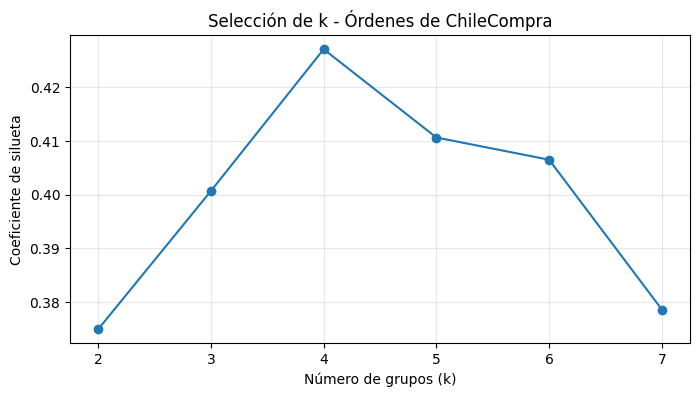

In [62]:

# Actividad 3.2 - Paso 3: selección de k

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd

# Valores de k que evaluaremos
valores_k = range(2, 8)

# Guardar resultados
resultados_k = []

for k in valores_k:

    # Crear y entrenar K-Means
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_mio_std)

    # Calcular el coeficiente de silueta
    silueta = silhouette_score(X_mio_std, etiquetas)

    # Guardar la evaluación
    resultados_k.append({
        "k": k,
        "silueta": silueta,
        "inercia": modelo.inertia_
    })

# Tabla comparativa
tabla_k = pd.DataFrame(resultados_k)

print("Comparación de valores de k:")
display(tabla_k.round(4))

# Gráfico de silueta
plt.figure(figsize=(8, 4))
plt.plot(tabla_k["k"], tabla_k["silueta"], marker="o")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Coeficiente de silueta")
plt.title("Selección de k - Órdenes de ChileCompra")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()


**Selección del número de grupos mediante el coeficiente de silueta**

Se aplicó el algoritmo K-Means sobre 336 órdenes de compra, utilizando dos atributos estandarizados: el logaritmo del monto neto y el mes de compra.

Se evaluaron seis configuraciones, desde k=2 hasta k=7. El coeficiente de silueta más elevado se obtuvo con k=4 (0,4271), seguido de k=5 (0,4106) y k=6 (0,4065).

Por lo tanto, se selecciona provisionalmente k=4, debido a que presenta la mayor silueta entre los valores evaluados, sin aumentar innecesariamente la complejidad del modelo.

No obstante, el coeficiente obtenido sugiere una separación moderada entre los grupos. En consecuencia, será necesario caracterizar los segmentos y comprobar su estabilidad antes de considerarlos patrones sólidos.

La elección implica renunciar a una segmentación más detallada con cinco o más grupos, pero permite conservar la configuración que obtuvo la mejor separación relativa según la métrica utilizada.

In [63]:

# Actividad 3.2 - Paso 4: caracterización de grupos

# Entrenar K-Means con el k seleccionado
k_elegido = 4

modelo_mio = KMeans(
    n_clusters=k_elegido,
    random_state=42,
    n_init=10
)

# Asignar cada orden a un grupo
mio["grupo"] = modelo_mio.fit_predict(X_mio_std)

# Resumir las características de cada grupo
resumen_grupos = mio.groupby("grupo").agg(
    ordenes=("codigoOC", "count"),
    monto_mediano=("MontoNetoOC_CLP", "median"),
    monto_promedio=("MontoNetoOC_CLP", "mean"),
    log_monto_medio=("log_monto_neto", "mean"),
    mes_promedio=("mes_compra", "mean")
)

# Agregar porcentaje de órdenes por grupo
resumen_grupos["porcentaje"] = (
    resumen_grupos["ordenes"] / len(mio) * 100
)

print("Características de los cuatro grupos:")
display(resumen_grupos.round(2))

# Distribución de mecanismos por grupo
print("\nMecanismos de contratación por grupo (%):")
display(
    pd.crosstab(
        mio["grupo"],
        mio["MecanismoCompra"],
        normalize="index"
    ).mul(100).round(1)
)

# Distribución mensual por grupo
print("\nMeses de compra por grupo:")
display(
    pd.crosstab(
        mio["grupo"],
        mio["mes_compra"]
    )
)


Características de los cuatro grupos:


,ordenes,monto_mediano,monto_promedio,log_monto_medio,mes_promedio,porcentaje
grupo,,,,,,
0,51,6233600.44,71360118.25,7.02,2.02,15.18
1,123,403940.00,542843.02,5.58,3.21,36.61
2,71,6508722.25,26005533.24,7.03,5.15,21.13
3,91,369900.00,499233.97,5.53,5.59,27.08



Mecanismos de contratación por grupo (%):


MecanismoCompra,CompraAgil,ConvenioMarco,Licitacion,TratoDirecto
grupo,,,,
0,35.3,9.8,37.3,17.6
1,50.4,33.3,10.6,5.7
2,28.2,25.4,38.0,8.5
3,56.0,27.5,9.9,6.6



Meses de compra por grupo:


mes_compra,1,2,3,4,5,6
grupo,,,,,,
0,14,22,15,0,0,0
1,2,24,43,54,0,0
2,0,0,0,16,28,27
3,0,0,0,0,37,54


### Actividad 3.2 — Caracterización de los grupos

Se aplicó K-Means a 336 órdenes de compra de ChileCompra, utilizando como atributos el logaritmo del monto neto y el mes de contratación, previamente estandarizados. Se seleccionó k=4 debido a que presentó el mayor coeficiente de silueta entre las configuraciones evaluadas (0,4271).

**Grupo 0 — Contrataciones de mayor monto del inicio del semestre:** comprende 51 órdenes (15,18 %), con una mediana de $6.233.600 CLP y un mes promedio de 2,02. Sus operaciones se concentran entre enero y marzo, con una participación de licitaciones del 37,3 %.

**Grupo 1 — Contrataciones de menor monto del inicio y mitad del semestre:** contiene 123 órdenes (36,61 %), con una mediana de $403.940 CLP y un mes promedio de 3,21. Predominan Compra Ágil (50,4 %) y Convenio Marco (33,3 %).

**Grupo 2 — Contrataciones de mayor monto de la segunda mitad del semestre:** incluye 71 órdenes (21,13 %), con una mediana de $6.508.722 CLP y un mes promedio de 5,15. Las órdenes se distribuyen entre abril y junio, y las licitaciones representan el 38,0 %.

**Grupo 3 — Contrataciones de menor monto del cierre del semestre:** comprende 91 órdenes (27,08 %), con una mediana de $369.900 CLP y un mes promedio de 5,59. Sus operaciones se concentran en mayo y junio, predominando Compra Ágil (56,0 %).

**Conclusión:** La segmentación permitió identificar cuatro perfiles diferenciados principalmente por magnitud monetaria y período de contratación. Se observa una mayor presencia relativa de licitaciones en los segmentos de montos elevados y de Compra Ágil en los segmentos de montos menores.

Sin embargo, como el mes fue utilizado directamente para construir los grupos, su diferenciación temporal es parcialmente consecuencia de las variables seleccionadas. Además, la silueta de 0,4271 indica una separación moderada, por lo que estos perfiles deben considerarse exploratorios hasta comprobar su estabilidad.

Los segmentos podrían servir para orientar análisis específicos de contrataciones por importe y período, pero no constituyen por sí solos evidencia suficiente para establecer diferencias causales o tomar decisiones definitivas.

Umbral percentil 97: 1.307
Órdenes anómalas: 11


,codigoOC,RegionOrigen,MecanismoCompra,mes_compra,MontoNetoOC_CLP,grupo,distancia
225,1003780-2-SE26,Metropolitana,TratoDirecto,2,2.016712e+09,0,2.660
194,1261-2-SE26,Metropolitana,Licitacion,3,3.244430e+08,0,1.852
40,624-379-CM25,Coquimbo,ConvenioMarco,1,2.880756e+08,0,1.805


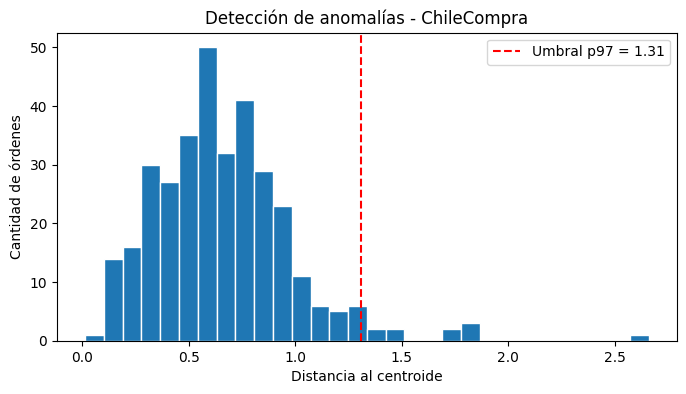

In [64]:

# Actividad 3.2 - Paso 5: detección de anomalías

import numpy as np
import matplotlib.pyplot as plt

# Obtener los centroides del modelo
centroides_mio = modelo_mio.cluster_centers_

# Calcular distancia de cada orden a su centroide
mio["distancia"] = np.linalg.norm(
    X_mio_std - centroides_mio[modelo_mio.labels_],
    axis=1
)

# Definir umbral mediante percentil 97
umbral_mio = mio["distancia"].quantile(0.97)

# Identificar órdenes anómalas
anomalias_mio = mio[
    mio["distancia"] > umbral_mio
].copy()

print(f"Umbral percentil 97: {umbral_mio:.3f}")
print(f"Órdenes anómalas: {len(anomalias_mio)}")

# Mostrar las tres órdenes más extremas
columnas = [
    "codigoOC",
    "RegionOrigen",
    "MecanismoCompra",
    "mes_compra",
    "MontoNetoOC_CLP",
    "grupo",
    "distancia"
]

top_3_anomalias = (
    anomalias_mio
    .sort_values("distancia", ascending=False)
    .head(3)
)

display(top_3_anomalias[columnas].round(3))

# Visualizar distribución de las distancias
plt.figure(figsize=(8, 4))
plt.hist(mio["distancia"], bins=30, edgecolor="white")

plt.axvline(
    umbral_mio,
    color="red",
    linestyle="--",
    label=f"Umbral p97 = {umbral_mio:.2f}"
)

plt.xlabel("Distancia al centroide")
plt.ylabel("Cantidad de órdenes")
plt.title("Detección de anomalías - ChileCompra")
plt.legend()
plt.show()


### Actividad 3.2 — Detección e interpretación de anomalías en ChileCompra

Se calculó la distancia euclidiana de cada una de las 336 órdenes de compra respecto del centroide de su grupo, utilizando los atributos estandarizados `log_monto_neto` y `mes_compra`.

Se estableció el percentil 97 como umbral exploratorio (1,307), identificando 11 órdenes anómalas, equivalentes al 3,27 % del conjunto.

**1. Orden 1003780-2-SE26:** Corresponde a un Trato Directo de la Región Metropolitana, registrado en febrero de 2026, por aproximadamente $2.016,71 millones CLP. Presenta la mayor distancia al centroide (2,660). Su magnitud explica aproximadamente el 91,5 % del monto acumulado de febrero. Se considera provisionalmente un posible fenómeno real de contratación extraordinaria, pendiente de verificación documental.

**2. Orden 1261-2-SE26:** Corresponde a una Licitación de la Región Metropolitana, registrada en marzo, por aproximadamente $324,44 millones CLP. Presenta una distancia de 1,852. Aunque su monto es considerablemente superior al valor típico del conjunto, el mecanismo de contratación y la magnitud no constituyen por sí solos evidencia de error. Se clasifica provisionalmente como posible fenómeno real.

**3. Orden 624-379-CM25:** Corresponde a una contratación mediante Convenio Marco de la Región de Coquimbo, registrada en enero, por aproximadamente $288,08 millones CLP. Presenta una distancia de 1,805. El importe es inusual respecto de la distribución general, pero no existe evidencia suficiente para considerarlo incorrecto. Se clasifica provisionalmente como posible fenómeno real.

**Conclusión:** Las tres órdenes más extremas pertenecen al grupo de contrataciones de mayor monto del inicio del semestre y destacan principalmente por su magnitud monetaria.

No se identificaron, mediante este procedimiento estadístico, evidencias concluyentes de errores de registro. Por lo tanto, se recomienda conservar las observaciones y verificar sus antecedentes en la fuente original antes de realizar correcciones.

El umbral del percentil 97 permite priorizar la revisión de un conjunto reducido de casos, pero su elección es exploratoria y no implica que las órdenes detectadas correspondan a irregularidades administrativas.

---
## Parte 4 · Validación: ¿el hallazgo se sostiene?

Encontrar un patrón es la parte fácil. La pregunta profesional es si ese patrón **seguiría estando** con otros datos, otra muestra u otra semilla.

### 4.1 Dos preguntas, dos destinos

Vamos a intentar predecir dos cosas distintas a partir del perfil de cada medidor, con el mismo método y los mismos datos:

- **La punta de consumo** (percentil 95), a partir del consumo medio, la variabilidad y la razón nocturna.
- **La razón nocturna**, a partir del consumo medio, la variabilidad y la punta.

Una de las dos se puede aprender. La otra no. Y el modelo no te lo va a decir: tienes que medirlo.

In [65]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor

def comparar(y, columnas, titulo):
    Xv = perfil[columnas]
    X_tr, X_te, y_tr, y_te = train_test_split(Xv, y, test_size=0.3, random_state=SEMILLA)
    print(titulo)
    print(f"{'profundidad':>12s} {'R² train':>10s} {'R² test':>10s}")
    for prof in (2, 4, 8, 16, None):
        m = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA).fit(X_tr, y_tr)
        print(f'{str(prof):>12s} {m.score(X_tr, y_tr):10.3f} {m.score(X_te, y_te):10.3f}')
    print()

comparar(perfil['punta'],
         ['consumo_medio', 'variabilidad', 'razon_nocturna'],
         'A · Predecir la PUNTA de consumo')
comparar(perfil['razon_nocturna'],
         ['consumo_medio', 'variabilidad', 'punta'],
         'B · Predecir la RAZÓN NOCTURNA')

A · Predecir la PUNTA de consumo
 profundidad   R² train    R² test
           2      0.892      0.853
           4      0.994      0.984
           8      1.000      0.997
          16      1.000      0.992
        None      1.000      0.992

B · Predecir la RAZÓN NOCTURNA
 profundidad   R² train    R² test
           2      0.060     -0.078
           4      0.182     -0.070
           8      0.569     -0.280
          16      0.970     -0.890
        None      1.000     -0.919



### Lo que muestran las dos tablas

**Caso A — hay relación.** El R² de entrenamiento sube a 1,00 y el de prueba lo acompaña, quedándose en torno a 0,99. El modelo aprendió algo que también vale fuera de los datos con que aprendió.

**Caso B — no hay relación.** Mira la columna de la derecha: el R² de prueba es **negativo** y empeora a medida que el árbol se hace más profundo, hasta cerca de −0,9 con profundidad ilimitada. Mientras tanto, el de entrenamiento llega a **1,000**: perfecto.

> **Un R² negativo significa que el modelo predice peor que decir siempre el promedio.** Y aun así, sobre los datos de entrenamiento acierta todo. Eso es exactamente el sobreajuste: el árbol no encontró un patrón, **memorizó las filas**.

La lección práctica: si alguien te presenta un modelo con 98 % de acierto y no te dice sobre qué datos se midió, la cifra no significa nada. Un modelo siempre puede memorizar sus propios datos.

### 4.2 Validación cruzada

Una sola partición puede tocarte fácil o difícil por azar. La validación cruzada parte los datos en k pliegues, entrena k veces y promedia. Lo valioso no es solo la media: es la **desviación**, que dice cuán estable es el resultado.

In [66]:
for etiqueta, y, cols in [
    ('A · punta         ', perfil['punta'],          ['consumo_medio', 'variabilidad', 'razon_nocturna']),
    ('B · razón nocturna', perfil['razon_nocturna'], ['consumo_medio', 'variabilidad', 'punta']),
]:
    for prof in (2, None):
        s = cross_val_score(DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA),
                            perfil[cols], y, cv=5, scoring='r2')
        print(f'{etiqueta}  prof={str(prof):>4s}  R² = {s.mean():7.3f} ± {s.std():.3f}   '
              f'pliegues {np.round(s, 2)}')

A · punta           prof=   2  R² =   0.849 ± 0.019   pliegues [0.82 0.87 0.87 0.83 0.85]
A · punta           prof=None  R² =   0.994 ± 0.003   pliegues [1.   1.   0.99 0.99 0.99]
B · razón nocturna  prof=   2  R² =  -0.104 ± 0.056   pliegues [-0.08 -0.19 -0.03 -0.07 -0.15]
B · razón nocturna  prof=None  R² =  -0.830 ± 0.250   pliegues [-0.35 -0.95 -0.9  -1.08 -0.86]


Dos lecturas:

- El caso A con profundidad ilimitada entrega **0,994 ± 0,003**: estable en los cinco pliegues.
- El caso B con profundidad ilimitada entrega algo como **−0,83 ± 0,25**. No solo es malo: es **inestable**. Según qué pliegue te toque, el resultado cambia mucho.

> **Reporta siempre media y desviación.** Un 0,80 ± 0,03 y un 0,80 ± 0,25 son resultados muy distintos, y el segundo no sostiene ninguna decisión.

### 4.3 Estabilidad de la segmentación

Un agrupamiento no tiene «respuesta correcta» contra la cual medirse, pero sí se puede comprobar si es **estable**: si con submuestras distintas aparece la misma estructura.

In [67]:
siluetas = []
for i in range(20):
    idx = np.random.RandomState(SEMILLA + i).choice(len(X), int(len(X) * 0.8), replace=False)
    km_i = KMeans(n_clusters=3, random_state=SEMILLA + i, n_init=10).fit(X[idx])
    siluetas.append(silhouette_score(X[idx], km_i.labels_))

siluetas = np.array(siluetas)
print(f'Silueta sobre 20 submuestras del 80 %: {siluetas.mean():.3f} ± {siluetas.std():.3f}')
print(f'Rango: [{siluetas.min():.3f}, {siluetas.max():.3f}]')

Silueta sobre 20 submuestras del 80 %: 0.348 ± 0.018
Rango: [0.323, 0.380]


### ✏️ Actividad 4.1 — Valida TU hallazgo

Toma el hallazgo principal de tu conjunto y estima su robustez con una de estas vías:

- Repite el análisis sobre 20 submuestras y reporta media ± desviación.
- Parte tus datos en dos mitades y comprueba si el patrón aparece en ambas.
- Si tienes una variable temporal, comprueba si el patrón se mantiene en períodos distintos.

Después responde: **¿este hallazgo sostiene una decisión, o solo sugiere una hipótesis?**

In [68]:
# Tu código aquí

# Actividad 4.1 - Validación de la segmentación

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración de la validación
n_repeticiones = 20
fraccion = 0.70
valores_k = [3, 4, 5]

# Generador aleatorio reproducible
rng = np.random.default_rng(42)

# Almacenar los resultados
resultados_validacion = []

for repeticion in range(n_repeticiones):

    # Seleccionar aleatoriamente el 70 % de las órdenes
    indices = rng.choice(
        len(X_mio),
        size=int(len(X_mio) * fraccion),
        replace=False
    )

    muestra = X_mio.iloc[indices]

    # Estandarizar nuevamente la submuestra
    escalador = StandardScaler()
    muestra_std = escalador.fit_transform(muestra)

    # Evaluar tres configuraciones de K-Means
    for k in valores_k:

        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        etiquetas = modelo.fit_predict(muestra_std)

        silueta = silhouette_score(
            muestra_std,
            etiquetas
        )

        resultados_validacion.append({
            "repeticion": repeticion + 1,
            "k": k,
            "silueta": silueta
        })

# Convertir los resultados a DataFrame
validacion = pd.DataFrame(resultados_validacion)

# Calcular media y desviación estándar
resumen_validacion = validacion.groupby("k")["silueta"].agg(
    ["mean", "std", "min", "max"]
)

print("Validación de 20 submuestras:")
display(resumen_validacion.round(4))

# Comprobar cuántas veces k=4 obtiene la mejor silueta
mejor_k = validacion.loc[
    validacion.groupby("repeticion")["silueta"].idxmax()
]

print("\nFrecuencia del mejor k:")
display(mejor_k["k"].value_counts().sort_index())

# Mostrar las 20 siluetas para k=4
print("\nResultados individuales para k=4:")
display(
    validacion[validacion["k"] == 4]
    [["repeticion", "silueta"]]
    .round(4)
)


Validación de 20 submuestras:


,mean,std,min,max
k,,,,
3,0.3996,0.0103,0.3796,0.4225
4,0.4292,0.0082,0.4171,0.4419
5,0.4093,0.0108,0.3915,0.4295



Frecuencia del mejor k:


,count
k,
4,20



Resultados individuales para k=4:


,repeticion,silueta
1,1,0.4409
4,2,0.4228
7,3,0.4374
10,4,0.4409
13,5,0.4280
16,6,0.4226
19,7,0.4326
22,8,0.4292
25,9,0.4171
28,10,0.4331


_Tu estimación de robustez y tu conclusión:_

### Actividad 4.1 — Validación y robustez del hallazgo

Se evaluó la robustez de la segmentación de ChileCompra mediante 20 submuestras aleatorias del 70 % del conjunto original, seleccionadas sin reemplazo dentro de cada repetición. En cada submuestra se estandarizaron nuevamente los atributos y se aplicó K-Means, comparando los valores k=3, k=4 y k=5 mediante el coeficiente de silueta.

**Resultados de validación:**

- k=3: silueta media de 0,3996 ± 0,0103.
- k=4: silueta media de 0,4292 ± 0,0082.
- k=5: silueta media de 0,4093 ± 0,0108.

El modelo con cuatro grupos obtuvo la mayor silueta media y presentó la menor desviación estándar. Además, k=4 fue la configuración con mejor puntuación en las 20 repeticiones realizadas.

La silueta media de k=4 (0,4292) resultó cercana a la obtenida con el conjunto completo (0,4271), lo que evidencia una estabilidad relativamente alta de la calidad de separación ante cambios en las observaciones utilizadas.

No obstante, el valor de silueta continúa indicando una separación moderada entre los grupos. Asimismo, esta validación no permite asegurar que la asignación individual de cada orden sea idéntica entre repeticiones ni que los patrones se reproduzcan en otros períodos.

**Conclusión — ¿El hallazgo sostiene una decisión o solo sugiere una hipótesis?**

Los resultados respaldan la existencia de perfiles monetarios y temporales relativamente estables dentro del conjunto analizado. Sin embargo, debido al alcance limitado de los datos y a la separación moderada entre segmentos, el hallazgo se considera principalmente una **hipótesis exploratoria respaldada por evidencia**, y no una base suficiente para tomar decisiones administrativas definitivas.

La segmentación puede orientar investigaciones posteriores sobre diferencias en los montos y mecanismos de contratación, pero requeriría validación con períodos adicionales y conjuntos independientes antes de sustentar decisiones de mayor impacto.


---
## Parte 5 · Volumen y costo computacional

El archivo `S4_Dataset_Grande_CDD.csv` tiene 280.800 filas y unos 13 MB en disco. Todavía cabe en memoria, y justamente por eso sirve para **medir** qué pasa cuando deje de caber.

In [69]:
import os, time

ruta = RUTA + 'S4_Dataset_Grande_CDD.csv'
print(f'Tamaño en disco: {os.path.getsize(ruta)/1024/1024:.1f} MB')

Tamaño en disco: 13.2 MB


### Estrategia A · leer todo

In [70]:
t0 = time.time()
completo = pd.read_csv(ruta, sep=';')
t_a = time.time() - t0
mem_a = completo.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_a:.2f} s · Memoria: {mem_a:.1f} MB · Filas: {len(completo):,}')

Tiempo: 0.30 s · Memoria: 68.0 MB · Filas: 280,800


Fíjate: **13 MB en disco se convierten en unos 78 MB en memoria**. El texto de las columnas `medidor_id`, `comuna` y `tarifa` se guarda como objetos de Python, mucho más pesados que en el archivo.

### Estrategia B · leer solo las columnas necesarias

In [71]:
t0 = time.time()
liviano = pd.read_csv(ruta, sep=';', usecols=['medidor_id', 'consumo_kwh'])
t_b = time.time() - t0
mem_b = liviano.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_b:.2f} s · Memoria: {mem_b:.1f} MB')
print(f'Reducción de memoria: {(1 - mem_b/mem_a)*100:.0f} %')

Tiempo: 0.20 s · Memoria: 16.9 MB
Reducción de memoria: 75 %


### Estrategia C · procesar por bloques

In [72]:
t0 = time.time()
parciales = []
for bloque in pd.read_csv(ruta, sep=';', chunksize=50_000):
    parciales.append(bloque.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count']))
por_bloques = pd.concat(parciales).groupby(level=0).sum()
t_c = time.time() - t0
print(f'Tiempo: {t_c:.2f} s · Memoria máxima: la de UN bloque, no la del archivo')
print(f'Medidores agregados: {len(por_bloques)}')

Tiempo: 0.32 s · Memoria máxima: la de UN bloque, no la del archivo
Medidores agregados: 260


In [73]:
# Comprobación obligatoria: ¿da lo mismo que en memoria?
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count'])
iguales = np.allclose(por_bloques.sort_index()['sum'], directo.sort_index()['sum'])
print('¿Mismo resultado?', iguales)

¿Mismo resultado? True


### La conclusión, que no es la esperada

Compara los tiempos. Procesar por bloques **no es más rápido**: suele ser igual o algo más lento, porque el archivo se recorre igual y además hay que unir los resultados parciales.

> **El procesamiento por bloques no hace las cosas más rápidas: las hace posibles.** Lo que cambia no es el tiempo, es el techo de memoria. Con este archivo la diferencia es irrelevante; con uno de 40 GB, la estrategia A simplemente no corre.

Esa distinción —entre lo que acelera y lo que habilita— es la que hay que tener clara al elegir herramienta. Recurrir a procesamiento distribuido para un archivo que cabe en memoria añade complejidad sin ganar nada.

In [74]:
print(f'A · todo el archivo : {t_a:5.2f} s · {mem_a:6.1f} MB')
print(f'B · dos columnas    : {t_b:5.2f} s · {mem_b:6.1f} MB')
print(f'C · por bloques     : {t_c:5.2f} s · memoria acotada al bloque')

A · todo el archivo :  0.30 s ·   68.0 MB
B · dos columnas    :  0.20 s ·   16.9 MB
C · por bloques     :  0.32 s · memoria acotada al bloque


### ✏️ Actividad 5.1

Responde en la celda siguiente: **¿a partir de qué tamaño de archivo cambiarías de estrategia, y por qué?** Toma como referencia la memoria disponible en tu entorno (en Google Colab, unos 12 GB).

Y una segunda: si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?

_Tu respuesta:_

### Actividad 5.1 — Volumen y costo computacional

**1. ¿A partir de qué tamaño de archivo cambiaría de estrategia y por qué?**

Considerando que Google Colab dispone de aproximadamente 12 GB de memoria RAM, comenzaría a evaluar un cambio de estrategia cuando el archivo CSV alcanzara alrededor de 2–3 GB, dependiendo de su estructura y del consumo real de memoria.

Esto se debe a que el tamaño de un archivo en disco no equivale necesariamente a la memoria requerida para procesarlo. Al cargar datos en pandas y realizar operaciones como filtrados, agrupaciones o transformaciones, pueden generarse estructuras adicionales que aumentan el consumo de RAM.

Por lo tanto, utilizaría inicialmente pandas para conjuntos pequeños o medianos y, a medida que aumentara el volumen, consideraría la lectura selectiva de columnas, la optimización de tipos de datos y el procesamiento por bloques mediante `chunksize`.

El criterio definitivo sería el uso real de memoria y el rendimiento observado, no únicamente el tamaño del archivo.

**2. Si tuviera que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué haría y en qué orden?**

Dado que el archivo supera ampliamente la memoria disponible en Google Colab, utilizaría una estrategia de procesamiento por bloques siguiendo estos pasos:

1. **Inspeccionar la estructura del archivo:** identificar el separador, los nombres de las columnas y sus tipos de datos.
2. **Seleccionar las columnas necesarias:** cargar únicamente `comuna` y `consumo_kwh` mediante `usecols`, evitando almacenar información innecesaria.
3. **Leer el archivo por bloques:** utilizar `pd.read_csv()` con `chunksize` para procesar una cantidad limitada de registros en cada iteración.
4. **Calcular resultados parciales:** agrupar cada bloque por comuna y obtener la suma del consumo y la cantidad de registros válidos.
5. **Acumular los resultados:** combinar las sumas y los conteos de cada comuna a medida que se procesan los bloques.
6. **Calcular el promedio final:** dividir la suma total acumulada entre la cantidad de mediciones válidas de cada comuna.
7. **Verificar y guardar los resultados:** comprobar los conteos, revisar valores faltantes y guardar una tabla resumida con el consumo medio por comuna.

Esta estrategia permite procesar un archivo mayor que la memoria RAM disponible sin cargarlo completamente.

Si el volumen de datos o la complejidad del análisis aumentaran considerablemente, evaluaría herramientas como Dask, DuckDB o Spark, especialmente para consultas repetidas o procesamiento distribuido.

**Conclusión:** La elección de una estrategia de procesamiento debe considerar el tamaño de los datos, la memoria disponible y el costo computacional. Para un archivo de 40 GB, el procesamiento por bloques resulta una alternativa adecuada para calcular promedios por comuna de manera eficiente y reproducible.



---
## Cierre y versionado

In [75]:
mio.to_csv(RUTA + 'mi_conjunto_minado.csv', sep=';', index=False)
print('Guardado')

Guardado


In [76]:
# En una terminal:
# git add S4_Notebook_Laboratorio_CDD.ipynb mi_conjunto_minado.csv
# git commit -m 'Semana 4: mineria, validacion y volumen'
# git push


**Enlace a mi repositorio:** _https://github.com/Sayrinix/Entrega_S4_CDD$0_

---

## Antes de entregar

- [ ] Al menos una técnica de minería aplicada a mi conjunto e interpretada
- [ ] Los grupos obtenidos tienen nombre descriptivo, no número
- [ ] Me pronuncié sobre las anomalías: error de registro o fenómeno real
- [ ] Un hallazgo validado, con su estimación de robustez (media ± desviación)
- [ ] Comparación del costo computacional de dos estrategias, con cifras propias
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

_Ciencia de Datos · Advance UCSC · Semana 4_